<a href="https://colab.research.google.com/github/KineticBlaze23/Metodos-Numericos/blob/main/Deber_Newton_y_Secante.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Escuela Politecnica Nacional**
##**Metodos Numericos**
##**Nombre:** Fabio Pillajo
##**Fecha:** 22/11/2026
##**Curso:** GR1CC

##Metodo de Newton

In [35]:
import numpy as np
import matplotlib.pyplot as plt
def newton_raphson(f, df, p0, TOL=1e-6, N0=50):
    """Algoritmo 2.3. Devuelve (p, historia), con historia = [p0, p1, ..., p]."""
    historia = [p0]
    i = 1
    while i <= N0:
        d = df(p0)
        if d == 0:
            raise ZeroDivisionError(f"f'(p0) = 0 en p0 = {p0}: la tangente es horizontal")
        p = p0 - f(p0) / df(p0)                          # COMPLETE: Paso 3, usando d
        historia.append(p)             # COMPLETE
        if abs(p - p0) < TOL:                          # COMPLETE: Paso 4
            return p, historia
        i = i + 1
        p0 = p                         # COMPLETE: Paso 6
    raise RuntimeError(f"El método fracasó después de {N0} iteraciones")

# Metodo Secante

In [36]:
def secante(f, p0, p1, TOL=1e-6, N0=50):
    """Algoritmo 2.4. Devuelve (p, historia), con historia = [p0, p1, p2, ..., p]."""
    # Paso 1: i = 2; q0 = f(p0); q1 = f(p1); historia empieza con p0 y p1.
    i = 2
    q0 = f(p0)
    q1 = f(p1)
    historia = [p0, p1]

    # Paso 2: mientras i <= N0, haga los pasos 3 a 6.
    while i <= N0:
        # Si q1 == q0, la secante es horizontal: lance un ZeroDivisionError con un mensaje claro.
        if q1 == q0:
            raise ZeroDivisionError("División por cero: q1 == q0, la recta secante es horizontal.")

        # Paso 3: calcule p y agréguelo a la historia.
        p = p1 - q1 * (p1 - p0) / (q1 - q0)
        historia.append(p)

        # Paso 4: si |p - p1| < TOL, devuelva (p, historia).
        if abs(p - p1) < TOL:
            return p, historia

        # Paso 5: i = i + 1.
        i += 1

        # Paso 6: corra los puntos (p0, q0) <- (p1, q1) y (p1, q1) <- (p, f(p)).
        #         Es la única evaluación nueva de f en la iteración.
        p0, q0 = p1, q1
        p1, q1 = p, f(p)

    raise RuntimeError(f"El método fracasó después de {N0} iteraciones.")

##2. Analisis con Graficas

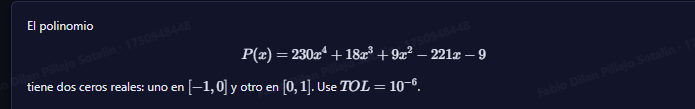

In [48]:
# Valor que converge utilizando la secante
p, historia_sec = secante(f, 0, 1, 10e-6)
print("*** SECANTE ***")
print(f"Valor p: {p:.6f}")

# Valor que converge utilizando Newton
raiz, historia_new = newton_raphson(f, dF, 0.5, 1e-6)
print("\n*** NEWTON ***")
print(f"Valor p: {raiz:.6f}")



*** SECANTE ***
Valor p: -0.040659

*** NEWTON ***
Valor p: -0.040659


##Grafica Secante

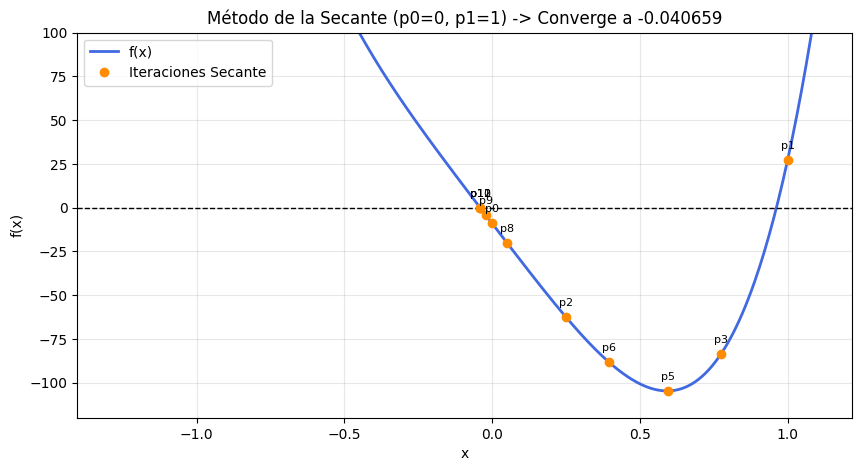

In [49]:
# Gráfica de la Secante
x = np.linspace(-1.0, 1.1, 400)
plt.figure(figsize=(10, 5))
plt.plot(x, f(x), label='f(x)', color='royalblue', linewidth=2)
plt.axhline(0, color='black', linewidth=1, linestyle='--')
plt.ylim(-120, 100)

pts_sec = np.array(historia_sec)
plt.plot(pts_sec, f(pts_sec), 'o', color='darkorange', label='Iteraciones Secante')
for i, px in enumerate(pts_sec):
    plt.annotate(f"p{i}", (px, f(px)), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8)

plt.title("Método de la Secante (p0=0, p1=1) -> Converge a -0.040659")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

##Grafica Newton


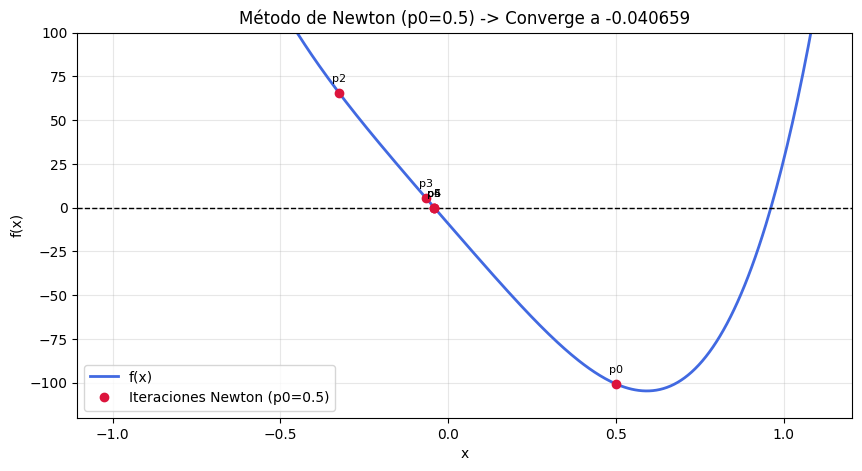

In [50]:
# Gráfica de Newton (p0 = 0.5)
x = np.linspace(-1.0, 1.1, 400)
plt.figure(figsize=(10, 5))
plt.plot(x, f(x), label='f(x)', color='royalblue', linewidth=2)
plt.axhline(0, color='black', linewidth=1, linestyle='--')
plt.ylim(-120, 100)

pts_new = np.array(historia_new)
plt.plot(pts_new, f(pts_new), 'o', color='crimson', label='Iteraciones Newton (p0=0.5)')
for i, px in enumerate(pts_new):
    plt.annotate(f"p{i}", (px, f(px)), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8)

plt.title("Método de Newton (p0=0.5) -> Converge a -0.040659")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

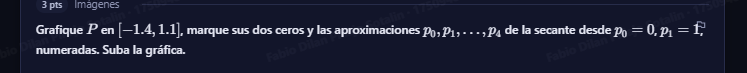

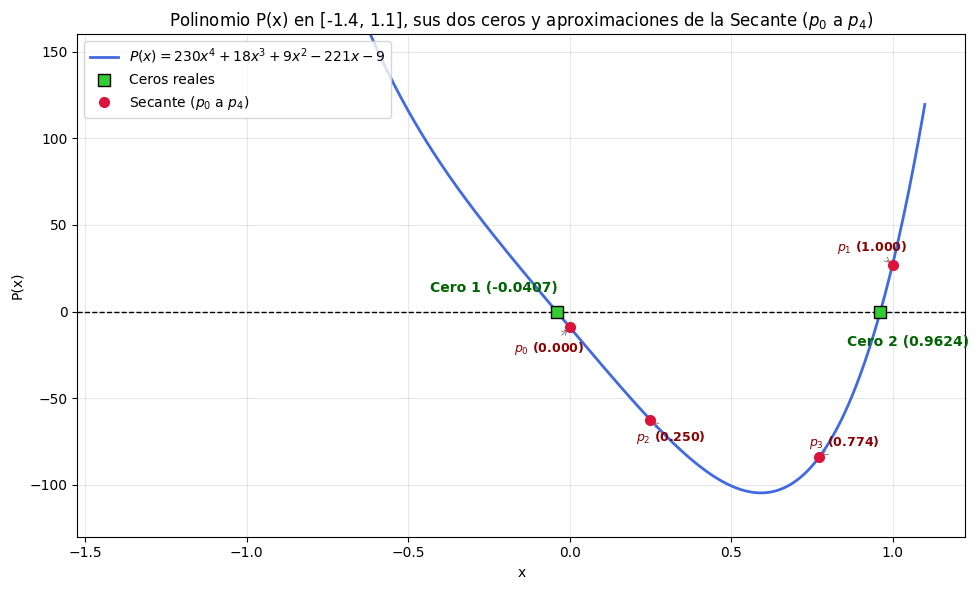

In [53]:
# Calculamos el cero positivo con Newton para marcar ambos ceros en la gráfica
cero_pos, _ = newton_raphson(f, dF, 0.9, 1e-6)
ceros = np.array([p, cero_pos])

# Tomamos las primeras 5 aproximaciones de historia_sec (p0, p1, p2, p3, p4)
pts = np.array(historia_sec[:5])

x = np.linspace(-1.4, 1.1, 500)
plt.figure(figsize=(10, 6))
plt.plot(x, f(x), label=r'$P(x) = 230x^4 + 18x^3 + 9x^2 - 221x - 9$', color='royalblue', linewidth=2)
plt.axhline(0, color='black', linewidth=1, linestyle='--')
plt.ylim(-130, 160)

# Marcar los dos ceros reales
plt.plot(ceros, [0, 0], 's', color='limegreen', markersize=9, markeredgecolor='black', zorder=5, label='Ceros reales')
plt.annotate(f"Cero 1 ({ceros[0]:.4f})", (ceros[0], 0), textcoords="offset points", xytext=(-45, 14), ha='center', fontweight='bold', color='darkgreen')
plt.annotate(f"Cero 2 ({ceros[1]:.4f})", (ceros[1], 0), textcoords="offset points", xytext=(20, -25), ha='center', fontweight='bold', color='darkgreen')

# Marcar y numerar p0, p1, ..., p4 de historia_sec
plt.plot(pts, f(pts), 'o', color='crimson', markersize=7, zorder=6, label='Secante ($p_0$ a $p_4$)')
offsets = [(-15, -18), (-15, 10), (15, -15), (18, 8), (0, -22)]
for i, (px, (dx, dy)) in enumerate(zip(pts, offsets)):
    plt.annotate(f"$p_{i}$ ({px:.3f})", (px, f(px)),
                 textcoords="offset points", xytext=(dx, dy),
                 ha='center', fontsize=9, fontweight='bold', color='darkred',
                 arrowprops=dict(arrowstyle='->', color='gray', lw=0.7))

plt.title("Polinomio P(x) en [-1.4, 1.1], sus dos ceros y aproximaciones de la Secante ($p_0$ a $p_4$)")
plt.xlabel("x")
plt.ylabel("P(x)")
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig("grafica_secante_P.png", dpi=300)
plt.show()

##3. Cuando no hay Raiz

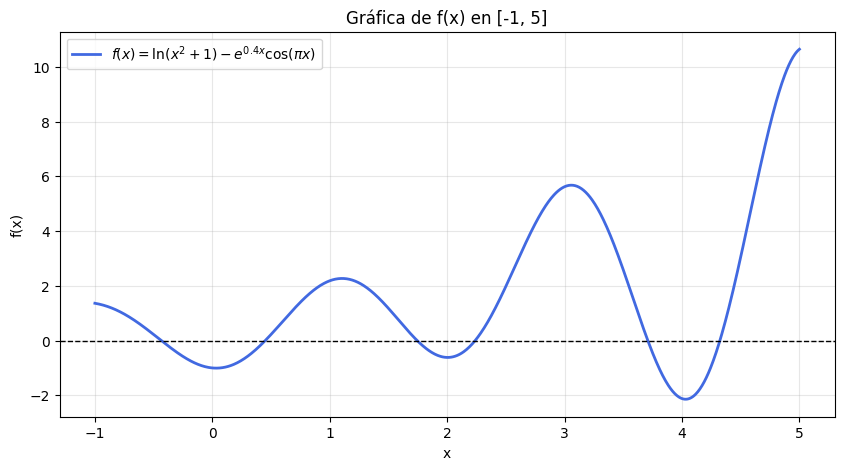

In [55]:
# Definir la función
f = lambda x: np.log(x**2 + 1) - np.exp(0.4*x) * np.cos(np.pi * x)

# Graficar en [-1, 5]
x = np.linspace(-1, 5, 1000)
plt.figure(figsize=(10, 5))
plt.plot(x, f(x), label=r'$f(x) = \ln(x^2 + 1) - e^{0.4x}\cos(\pi x)$', color='royalblue', linewidth=2)
plt.axhline(0, color='black', linewidth=1, linestyle='--')

plt.title("Gráfica de f(x) en [-1, 5]")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [60]:
#Vigesimoquinto cero positivo
n = 25
aprox = n - 0.5

# Usamos dos puntos iniciales muy cercanos a 24.5 en la secante
cero_25, historia = secante(f, aprox - 0.01, aprox + 0.01, TOL=1e-6)
print(f"Vigesimoquinto cero positivo: {cero_25:.6f}")

Vigesimoquinto cero positivo: 24.499887


In [64]:
#Ejecute newton con p0 = 0

f = lambda x : np.e**x
df = lambda x : np.e**x

raiz, historia = newton_raphson(f , df , 0)

RuntimeError: El método fracasó después de 50 iteraciones

In [71]:
def newton_raphson_residuo(f, df, p0, TOL=1e-6, N0=50):
    """Algoritmo 2.3. Devuelve (p, historia), con historia = [p0, p1, ..., p]."""
    historia = [p0]
    i = 1
    while i <= N0:
        d = df(p0)
        if d == 0:
            raise ZeroDivisionError(f"f'(p0) = 0 en p0 = {p0}: la tangente es horizontal")
        p = p0 - f(p0) / df(p0)                          # COMPLETE: Paso 3, usando d
        historia.append(p)             # COMPLETE
        if abs(f(p)) < TOL:                          # COMPLETE: Paso 4
            return p, historia
        i = i + 1
        p0 = p                         # COMPLETE: Paso 6
    raise RuntimeError(f"El método fracasó después de {N0} iteraciones")

In [68]:
raiz, historia = newton_raphson(f , df , 0)
print(raiz)

-14.0


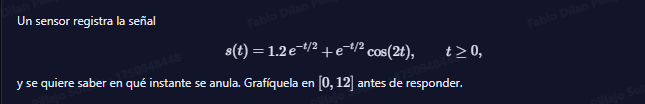

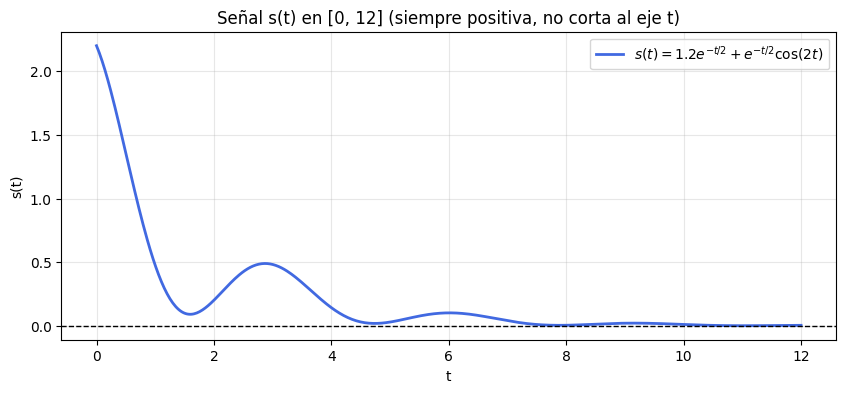

t0 = 0 -> t = 49.130290 | s(t-0.01) = 1.17e-11 | s(t+0.01) = 1.22e-11
t0 = 2 -> t = 49.130290 | s(t-0.01) = 1.17e-11 | s(t+0.01) = 1.22e-11
t0 = 3 -> t = 184.224760 | s(t-0.01) = 5.48e-41 | s(t+0.01) = 5.73e-41
t0 = 4 -> t = 26.721542 | s(t-0.01) = 3.17e-07 | s(t+0.01) = 3.16e-07


In [72]:
# Definir s(t) y su derivada s'(t)
s = lambda t: 1.2 * np.exp(-t/2) + np.exp(-t/2) * np.cos(2*t)
ds = lambda t: -0.6 * np.exp(-t/2) - 0.5 * np.exp(-t/2) * np.cos(2*t) - 2 * np.exp(-t/2) * np.sin(2*t)

# Gráfica en [0, 12]
t_vals = np.linspace(0, 12, 500)
plt.figure(figsize=(10, 4))
plt.plot(t_vals, s(t_vals), label=r'$s(t) = 1.2e^{-t/2} + e^{-t/2}\cos(2t)$', color='royalblue', linewidth=2)
plt.axhline(0, color='black', linewidth=1, linestyle='--')
plt.title("Señal s(t) en [0, 12] (siempre positiva, no corta al eje t)")
plt.xlabel("t")
plt.ylabel("s(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Prueba con Newton (criterio del residuo) desde t0 = 0, 2, 3 y 4
for t0 in [0, 2, 3, 4]:
    t_res, _ = newton_raphson_residuo(s, ds, t0, TOL=1e-6)
    print(f"t0 = {t0} -> t = {t_res:.6f} | s(t-0.01) = {s(t_res-0.01):.2e} | s(t+0.01) = {s(t_res+0.01):.2e}")

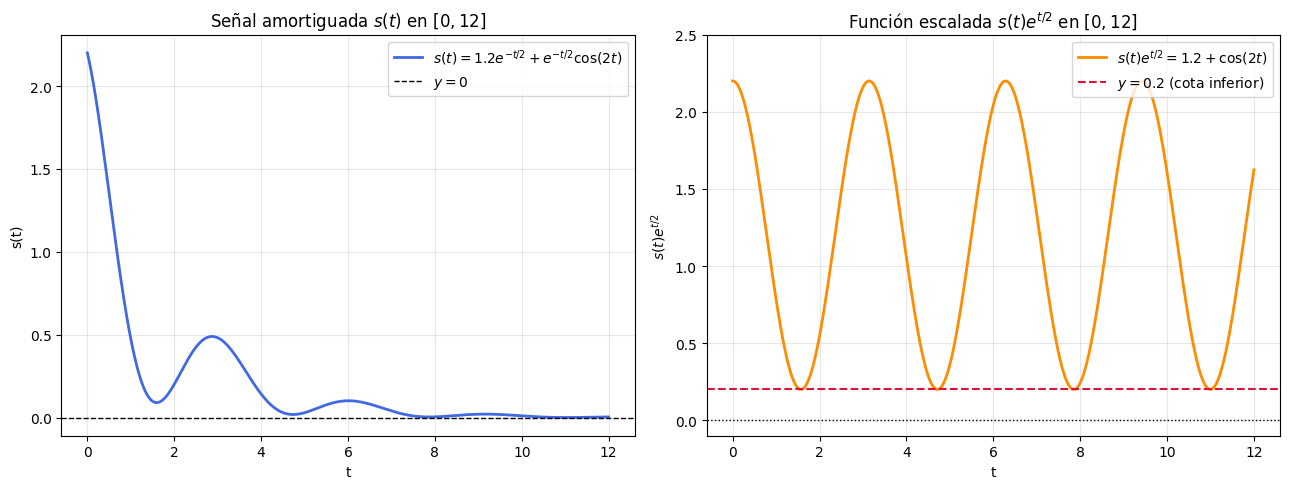

In [76]:
s_escalada = lambda t: s(t) * np.exp(t/2)
t = np.linspace(0, 12, 600)
# Crear figura con dos subgráficas lado a lado (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --- Gráfica izquierda: s(t) en [0, 12] ---
ax1.plot(t, s(t), color='royalblue', linewidth=2, label=r'$s(t) = 1.2e^{-t/2} + e^{-t/2}\cos(2t)$')
ax1.axhline(0, color='black', linewidth=1, linestyle='--', label=r'$y = 0$')
ax1.set_title(r'Señal amortiguada $s(t)$ en $[0, 12]$')
ax1.set_xlabel('t')
ax1.set_ylabel('s(t)')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right')

# --- Gráfica derecha: s(t)*e^(t/2) con la recta y = 0.2 ---
ax2.plot(t, s_escalada(t), color='darkorange', linewidth=2, label=r'$s(t)e^{t/2} = 1.2 + \cos(2t)$')
ax2.axhline(0.2, color='crimson', linewidth=1.5, linestyle='--', label=r'$y = 0.2$ (cota inferior)')
ax2.axhline(0, color='black', linewidth=1, linestyle=':')
ax2.set_ylim(-0.1, 2.5)
ax2.set_title(r'Función escalada $s(t)e^{t/2}$ en $[0, 12]$')
ax2.set_xlabel('t')
ax2.set_ylabel(r'$s(t)e^{t/2}$')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig("grafica_lado_a_lado_s.png", dpi=300)
plt.show()

In [77]:
import numpy as np
from scipy.optimize import newton

raiz, info = newton(np.exp, 0, fprime=np.exp, maxiter=1000, full_output=True)
print(raiz, info.converged, np.exp(raiz))

-746.0 True 0.0


## 4. Convergencia en una grafica

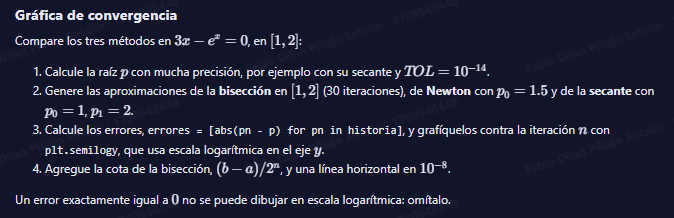

In [81]:
# Definir la función f(x) = 3x - e^x y su derivada df(x) = 3 - e^x
f = lambda x: 3*x - np.exp(x)
df = lambda x: 3 - np.exp(x)

# Tu función de Bisección
def biseccion(f, a, b, TOL=1e-14, N0=30):
    """Devuelve (p, historia), con historia = [(a, b, p) por iteración]."""
    FA = f(a)
    historia = []
    i = 1
    while i <= N0:
        p = a + (b-a)/2                                     # COMPLETE: punto medio estable
        FP = f(p)
        historia.append((a,b,p))                            # COMPLETE: (a, b, p)
        if FP == 0 or (b-a)/2 < TOL:                        # COMPLETE: parada por TOL
            return p, historia
        i = i + 1
        if FA * FP > 0:
            a = p
            FA = FP                                         # COMPLETE: mover a y FA
        else:
            b = p                                           # COMPLETE: mover b
    raise RuntimeError(f"fracasó después de {N0} iteraciones")



In [88]:
# 1. Calcular la raíz p con mucha precisión (TOL = 1e-14)
p, _ = secante(f, 1.0, 2.0, TOL=1e-14)
print(f"Raíz exacta de referencia (p): {p:.15f}")

# 2. Generar las aproximaciones de los tres métodos
# Con TOL=1e-9 y N0=30, biseccion hace exactamente 30 iteraciones ((2-1)/2^30 = 9.31e-10 < 1e-9)
_, hist_bis_tuplas = biseccion(f, 1.0, 2.0, TOL=1e-9, N0=30)
hist_bis = [fila[2] for fila in hist_bis_tuplas]  # Extraer solo p de cada tupla (a, b, p)

_, hist_new = newton_raphson(f, df, 1.5, TOL=1e-14)
_, hist_sec = secante(f, 1.0, 2.0, TOL=1e-14)

Raíz exacta de referencia (p): 1.512134551657842


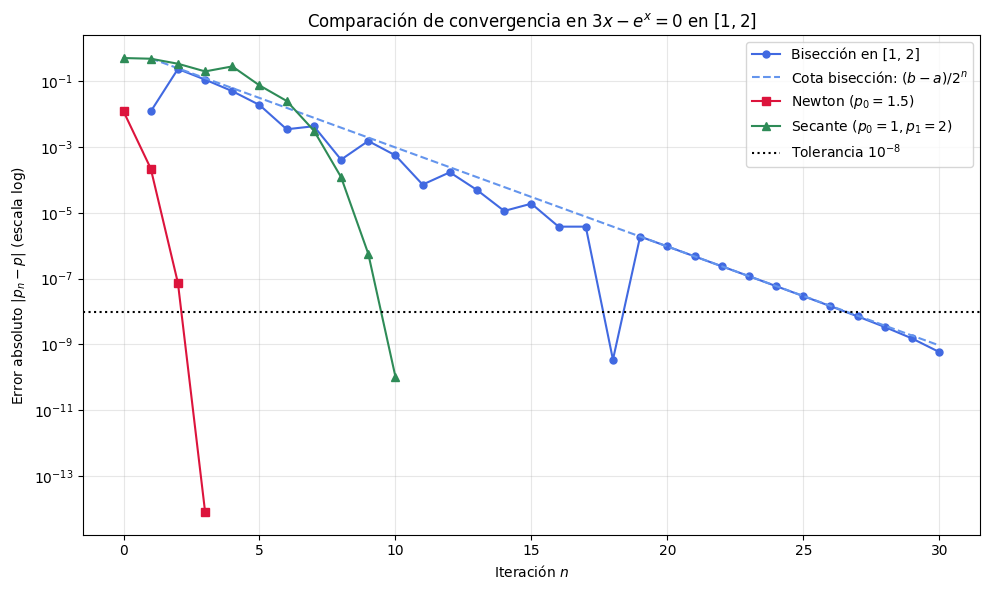

In [89]:
# 3. Calcular errores y omitir los que sean exactamente 0
def obtener_puntos_error(historia, p_exacta, n_inicial=1):
    ns = []
    errores = []
    for idx, pn in enumerate(historia):
        err = abs(pn - p_exacta)
        if err > 0:
            ns.append(n_inicial + idx)
            errores.append(err)
    return ns, errores

n_bis, err_bis = obtener_puntos_error(hist_bis, p, n_inicial=1)
n_new, err_new = obtener_puntos_error(hist_new, p, n_inicial=0)
n_sec, err_sec = obtener_puntos_error(hist_sec, p, n_inicial=0)

# 4. Cota teórica de la bisección: (b - a) / 2^n
n_cota = np.arange(1, len(hist_bis) + 1)
cota_bis = (2.0 - 1.0) / (2.0 ** n_cota)

# Gráfica en escala
plt.figure(figsize=(10, 6))

plt.semilogy(n_bis, err_bis, 'o-', color='royalblue', markersize=5, label='Bisección en [1, 2]')
plt.semilogy(n_cota, cota_bis, '--', color='cornflowerblue', linewidth=1.5, label=r'Cota bisección: $(b - a)/2^n$')
plt.semilogy(n_new, err_new, 's-', color='crimson', markersize=6, label='Newton ($p_0 = 1.5$)')
plt.semilogy(n_sec, err_sec, '^-', color='seagreen', markersize=6, label='Secante ($p_0 = 1, p_1 = 2$)')

# Línea horizontal de referencia en 10^-8
plt.axhline(1e-8, color='black', linestyle=':', linewidth=1.5, label=r'Tolerancia $10^{-8}$')

plt.title(r"Comparación de convergencia en $3x - e^x = 0$ en $[1, 2]$")
plt.xlabel("Iteración $n$")
plt.ylabel(r"Error absoluto $|p_n - p|$ (escala log)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("grafica_convergencia.png", dpi=300)
plt.show()